# Task 1: Data Exploration and Preprocessing

By: Yiwei GONG

**Data usage:**
Table included: 
- bike_types.csv
- bikes.csv
- cities.csv
- city_areas.csv(external)
- stations.csv
- trips_small.csv

Table excluded:
- stations_status.csv

**Reference:**
Waldner, F., Balke, G., Rech, F. et al. Data-driven insights into (E-)bike-sharing: mining a large-scale dataset on usage and urban characteristics: descriptive analysis and performance modeling. Transportation 52, 2433–2473 (2025). https://doi.org/10.1007/s11116-025-10661-2

**Note:** This task largely references to the "Preprocessing and descriptive analysis" section of the referenced work.


## 1. Preprocessing

In this section, we select valid bikes and cities, that are, bikes with trip records in trips_small.csv and known propulsion types in bike_types.csv, and cities with trip records in trips_small.csv and "owning" at least 10 bikes according to our definition.

We define the data hierarchy as **city level** and **bike level**. We call each city a bike sharing system (BSS). In each BSS numerous bikes and stations are operated.

We include one external dataset from https://github.com/TUMFTM/european-bike-sharing-dataset to get the operating areas of the cities concerned. 

---



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# static table
cities = pd.read_csv("../data/cities.csv")
stations = pd.read_csv(("../data/stations.csv"))
bikes = pd.read_csv(("../data/bikes.csv"))
bike_types = pd.read_csv(("../data/bike_types.csv"))

# dynamic table
trips = pd.read_csv(("../data/trips_small.csv"))

# Use external data from https://github.com/TUMFTM/european-bike-sharing-dataset/blob/main/sample/city_areas.csv
areas = pd.read_csv("../data/city_areas.csv")


### Selection of valid bikes

We approach the data from **bike level** first.

We have discovered that bikes.csv has 88436 bikes, but trips_small.csv has trip records of only 26424 bikes. From our analysis we exclude bikes that has no trip records.

We also exclude bikes with unknown propulsion type (null propulsion_type in bike_types.csv) from our analysis.


In [3]:
# link bikes to their propulsion types
bike_propulsion_type = (
    bikes[["id", "bike_type_id"]]
    .rename(columns={"id": "bike_id"})
    .merge(
        bike_types[["id", "propulsion_type"]],
        left_on="bike_type_id",
        right_on="id",
        how="left",
    )
    .drop(columns="id")
)

# select bikes with known propulsion types
known_propulsion_bikes = bike_propulsion_type.dropna(subset=["propulsion_type"])
bikes_valid = known_propulsion_bikes[
    known_propulsion_bikes["bike_id"].isin(trips["bike_id"])
].copy()

print(f"Bikes with known propulsion type: {known_propulsion_bikes['bike_id'].nunique()}")
print(f"Valid bikes with trip records and known propulsion type: {bikes_valid['bike_id'].nunique()}")


Bikes with known propulsion type: 87386
Valid bikes with trip records and known propulsion type: 25833


### Bike's belonging problem

Now we start to bridge **bike level** data with **city level** data. Remember in our terminology a city is referred to as a bike sharing system (BSS).

The scale of a BSS is directly linked to the number of bikes the system has. Since a bike can have trips records in multiple cities, we assign a **primary city** for each bike, i.e. the city that "owns" this bike. A bike's primary city is defined as the city where it has the longest **total trip duration**.



In [4]:
bike_city_durations = (
    trips.loc[trips["bike_id"].isin(bikes_valid["bike_id"])]
    .groupby(["city_id", "bike_id"], as_index=False)["duration"]
    .sum()
    .rename(columns={"duration": "total_duration"})
)
bike_primary_city = (
    bike_city_durations.sort_values("total_duration", ascending=False)
    .drop_duplicates(subset="bike_id")[["city_id", "bike_id"]]
)
cities_valid = bike_primary_city["city_id"].drop_duplicates()

print(f"Number of cities in cities.csv: {cities['id'].nunique()}")
print(f"Number of cities appearing in trips_small.csv: {trips['city_id'].nunique()}")
print(f"Cities with trips from valid bikes: {bike_city_durations['city_id'].nunique()}")
print(f"Primary cities assigned: {bike_primary_city['city_id'].nunique()}")
print(f"Valid cities retained: {cities_valid.shape[0]}")


Number of cities in cities.csv: 267
Number of cities appearing in trips_small.csv: 185
Cities with trips from valid bikes: 185
Primary cities assigned: 184
Valid cities retained: 184


Note that among the 185 cities, one city is not a "primary" city because for all bikes that have trips in it, they have longer trip durations in another city. We exclude this city from our analysis since it is not a representitive city.

### Selection of valid cities

**city_bikes** city_id | n_bikes

Now that every city has been granted with their bike ownership, we can approach the data at the **city level**. 

In order for a city to qualify as a bike sharing system (BSS), it needs to reach a certain scale. Here we define the minimum qualifying scale as 10 bikes. Thus cities with fewer than 10 bikes will be excluded from our subsequent analysis.

In this section we count the number of bikes in each city. 


In [5]:
# combine bikes, their propulsion types, and their primary city
city_bike_propulsion = bike_propulsion_type.merge(
    bike_primary_city, on="bike_id", how="inner"
)

# n_bikes in each city
city_bikes = (
    city_bike_propulsion.groupby("city_id")["bike_id"]
    .count()
    .reset_index(name="n_bikes")
)

# select sizable cities only
city_size = city_bikes.loc[city_bikes["n_bikes"] >= 10].copy()
excluded_cities = len(city_bikes) - len(city_size)
city_bike_propulsion = city_bike_propulsion[
    city_bike_propulsion["city_id"].isin(city_size["city_id"])
]
print(f"Cities excluded for having fewer than 10 bikes: {excluded_cities}")
print(f"Cities retained after size filtering: {len(city_size)}")


Cities excluded for having fewer than 10 bikes: 6
Cities retained after size filtering: 178


### Valid data accquired.

**Now we have got both valid bikes and valid cities, we will conduct the subsequent work only using these valid data.**

### By organisational form: 143 station based, 35 free floating (including hybrid).

We categorize BSS by its organisational form. A BSS is stational based if all bikes need to be returned to official stations (i.e. `return_to_official_only == TRUE`). If not all, it can be either a fully free floating system (no bikes need to be returned to stations) or a hybrid one (part of bikes need to be returned to station). We do not further distinguish between fully free floating and hybrid systems, but treat them both as free floating.

By this categorization, 143 BSS are station based, and 35 are free floating.

In [6]:
city_organization_form = (
    cities.merge(city_size[["city_id"]], left_on="id", right_on="city_id", how="inner")
    [["id", "return_to_official_only"]]
    .rename(columns={"id": "city_id"})
)
print("Cities by organizational form:")
print(city_organization_form["return_to_official_only"].value_counts())


Cities by organizational form:
return_to_official_only
True     143
False     35
Name: count, dtype: int64


### By propulsion type: 131 conventional, 36 mixed, 11 electric.

We also categorize BSSs by propulsion type: a city with 100% of human powered bikes is a conventional BSS, one with 0% human powered bikes is (purely) electric, while one in between is mixed.

By this categorization, 131 BSS are conventional, 36 are mixed, and 11 are electric.

In [7]:
# Categorize each city by its share of human-powered bikes.
city_human_share = (
    city_bike_propulsion.assign(
        is_human=city_bike_propulsion["propulsion_type"] == "human"
    )
    .groupby("city_id")["is_human"]
    .mean()
    .reset_index(name="proportion_of_human_powered_bikes")
)


def categorize_propulsion_type(proportion):
    if proportion == 1:
        return "conventional"
    if proportion == 0:
        return "electric"
    return "mixed"


city_human_share["type"] = city_human_share[
    "proportion_of_human_powered_bikes"
].apply(categorize_propulsion_type)
city_propulsion_type = city_human_share
print("Cities by propulsion type:")
print(city_propulsion_type["type"].value_counts())


Cities by propulsion type:
type
conventional    131
mixed            36
electric         11
Name: count, dtype: int64


Note that most of bikes are human powered:

In [8]:
propulsion_counts = bike_propulsion_type["propulsion_type"].value_counts()
print("Bikes by propulsion type:")
print(propulsion_counts)


Bikes by propulsion type:
propulsion_type
human              81530
electric_assist     5856
Name: count, dtype: int64


### Number of stations in each city


In [9]:
city_stations = (
    stations[stations["city_id"].isin(city_size["city_id"])]
    .groupby("city_id")["id"]
    .count()
    .reset_index(name="n_stations")
)

print("Station counts per city (first five rows):")
print(city_stations.head())


Station counts per city (first five rows):
   city_id  n_stations
0        7          37
1       23          29
2       64          44
3       88          41
4      128          44


### Number of bike racks in each city

We noticed that some special racks has negative values. Using AI to search info: there are two reporting schemes from Nextbike. If special_racak is positive, bike_racks means regular racks; if negative, bike_racks means number of total racks, the "-" sign means reserved for charging e-bikes. 

In [10]:
stations["total_racks"] = np.where(
    stations["special_racks"] < 0,
    stations["bike_racks"],                                      # subtractive: bike_racks is already gross total
    stations["bike_racks"] + stations["special_racks"].fillna(0) # additive: add both
)

# city_bikes we already have, now calculate city_racks
city_racks = (
    stations.groupby("city_id")["total_racks"]
    .sum()
    .reset_index(name="n_racks")
)


### Operation area

We use external data in city_areas.csv to calculate the operation area of each BSS. The data is acquired from [github](https://github.com/TUMFTM/european-bike-sharing-dataset). Refer to the github repo or Table 13 of the [paper](https://doi.org/10.1007/s11116-025-10661-2) for a more detailed explaination.


In [11]:
# Calculate operational area in square kilometers.
import geopandas as gpd
from shapely import wkt

areas["geometry"] = areas["geom_ewkt"].apply(lambda value: wkt.loads(value.split(";")[-1]))
gdf = gpd.GeoDataFrame(areas, geometry="geometry", crs="EPSG:4326")
gdf_projected = gdf.to_crs(epsg=6933)
gdf["area_sq_km"] = gdf_projected.geometry.area / 1_000_000
city_areas = gdf[["city_id", "area_sq_km"]]


### All in one city level dataframe and valid trip records.

After preprocessing, we get two dataframes: **city_all** includes all city-level features that we are intersted in, and **trips_valid** includes trips having known start time and made by bikes whose propulsion types are known. We will use these two dataframes in the next session.


In [12]:
city_all = (
    city_size
    .merge(city_stations, on="city_id")
    .merge(city_organization_form, on="city_id")
    .merge(city_propulsion_type, on="city_id")
    .merge(city_racks, on="city_id")
    .merge(city_areas, on="city_id")
    .drop(columns="proportion_of_human_powered_bikes")
)

trip_valid = (
    bike_propulsion_type.merge(trips, on="bike_id")
    .dropna(subset=["time_start"])
)
trips_valid = trip_valid

print(f"Final city-level dataframe: {city_all.shape[0]} cities, {city_all.shape[1]} columns.")
print(f"Final valid-trip dataframe: {trip_valid.shape[0]} trips, {trip_valid.shape[1]} columns.")


Final city-level dataframe: 178 cities, 7 columns.
Final valid-trip dataframe: 1161376 trips, 15 columns.


In [13]:
city_all.head()

,city_id,n_bikes,n_stations,return_to_official_only,type,n_racks,area_sq_km
0,7,456,37,False,conventional,24,23.608454
1,23,97,29,True,conventional,0,483.600722
2,64,340,44,True,conventional,0,61.150020
3,88,266,41,True,conventional,0,37.598203
4,128,235,44,True,conventional,251,11.922279


### Result
After preprocessing,

- we have identified 178 valid cities with 25803 valid bikes. These are cities that have bike trip records and have a fleet size of more than 10 bikes, and bikes that have trip records and identified propulsion type. 

- A majority (87.6% / 22621) of bikes are classic, human-powered bikes, the other (12.4% / 3212) are electric assisted bikes. 

- 87.1% or 22475 bikes belong to station based BSS, the other belong to free floating (including hybrid) BSS. 

- In total, there are 1159030 valid trips with a line-of-flight distance of 2075852 km.

In [14]:
# Summary of the final preprocessed datasets.
n_valid_cities = city_all["city_id"].nunique()
n_valid_bikes = city_all["n_bikes"].sum()
n_human_bikes = city_bike_propulsion["propulsion_type"].eq("human").sum()
n_typed_bikes = len(city_bike_propulsion)
n_station_based_bikes = city_all.loc[
    city_all["return_to_official_only"], "n_bikes"
].sum()
n_free_floating_bikes = n_valid_bikes - n_station_based_bikes
distance_km = trip_valid["distance"].sum() / 1000

print(f"Valid cities: {n_valid_cities}")
print(f"Valid bikes: {n_valid_bikes}")
print(
    f"Human-powered bikes: {n_human_bikes} "
    f"({n_human_bikes / n_typed_bikes:.1%}); "
    f"electric-assist bikes: {n_typed_bikes - n_human_bikes} "
    f"({(n_typed_bikes - n_human_bikes) / n_typed_bikes:.1%})."
)
print(
    f"Station-based bikes: {n_station_based_bikes}; "
    f"free-floating or hybrid bikes: {n_free_floating_bikes}."
)
print(f"Valid trips: {len(trip_valid)}")
print(f"Total trip distance: {distance_km:.1f} km")

Valid cities: 178
Valid bikes: 25803
Human-powered bikes: 22597 (87.6%); electric-assist bikes: 3206 (12.4%).
Station-based bikes: 22475; free-floating or hybrid bikes: 3328.
Valid trips: 1161376
Total trip distance: 2080923.1 km


<span style="color: red"><strong>IMPORTANT! READ THIS:</strong></span>

**The following cell export a dataframe to a csv file. This file is needed to run the notebook of Task 2.**

In [15]:
trips_valid.to_csv(
    "../data/trips_valid.csv",
    index=False
)

## 2. Descriptive Analysis

In this section, we perform a descriptive analysis on the dataset. 

We first manually categorize BSS into small, medium, and large according to their fleet size. 

We then add several features as **statistical indicators** that can provide more insights on these systems. 

We also investigate the temporal characteristics of trips conducted in varying systems and on different types of bikes.

### Categorizing BSS by size
We manually define the size of BSS:

- Small systems: 10 <= n_bikes <= 100
- Medium: 101 <= n_bikes <= 500
- Large: 501 <= n_bikes

Result:
- 97 small BSS
- 72 medium BSS
- 9 large BSS

In [16]:
def categorize_by_size(n_bikes):
    if n_bikes >= 501:
        return "large"
    if n_bikes >= 101:
        return "medium"
    return "small"


city_all["size"] = city_all["n_bikes"].apply(categorize_by_size)
print("Cities by system size:")
print(city_all["size"].value_counts())


Cities by system size:
size
small     97
medium    72
large      9
Name: count, dtype: int64


### Statistical Indicators

We calculate those indicators, and show their average values for small, medium, and large BSS in the table below.

In [17]:
bss_small = city_all[city_all["size"] == "small"]
bss_medium = city_all[city_all["size"] == "medium"]
bss_large = city_all[city_all["size"] == "large"]

In [18]:
# AI generated code
def get_indicator(bss):
    n_systems = len(bss)
    # Average per-system ratios; zero denominators are excluded as undefined.
    bikes_per_station = bss["n_bikes"].div(bss["n_stations"].replace(0, np.nan))
    bikes_per_rack = bss["n_bikes"].div(bss["n_racks"].replace(0, np.nan))
    bikes_per_sq_km = bss["n_bikes"].div(bss["area_sq_km"].replace(0, np.nan))
    stations_per_sq_km = bss["n_stations"].div(bss["area_sq_km"].replace(0, np.nan))

    return {
        "n_systems": n_systems,
        "avg_bikes_per_station": bikes_per_station.mean(),
        "avg_bikes_per_rack": bikes_per_rack.mean(),
        "avg_bikes_per_sq_km": bikes_per_sq_km.mean(),
        "avg_stations_per_sq_km": stations_per_sq_km.mean(),
        "share_station_based_bss_pct": bss["return_to_official_only"].mean() * 100,
        "share_mixed_propulsion_bss_pct": bss["type"].eq("mixed").mean() * 100,
        "share_electric_bss_pct": bss["type"].eq("electric").mean() * 100,
    }

In [19]:
# AI generated code
size_indicators = pd.DataFrame.from_dict(
    {
        "small": get_indicator(bss_small),
        "medium": get_indicator(bss_medium),
        "large": get_indicator(bss_large),
    },
    orient="index",
).rename_axis("size")
size_indicators

,n_systems,avg_bikes_per_station,avg_bikes_per_rack,avg_bikes_per_sq_km,avg_stations_per_sq_km,share_station_based_bss_pct,share_mixed_propulsion_bss_pct,share_electric_bss_pct
size,,,,,,,,
small,97,5.758213,1.567236,4.675725,0.844523,76.288660,20.618557,4.123711
medium,72,14.021020,2.691682,10.624351,1.083457,83.333333,19.444444,8.333333
large,9,60.087447,8.014312,39.070115,0.764905,100.000000,22.222222,11.111111


### Station occupancy and service density 

We first visualize the statistical distribution of station occupancy and service density for small, medium, and large BSS. For values related to stations and/or racks, we only consider station based BSS.

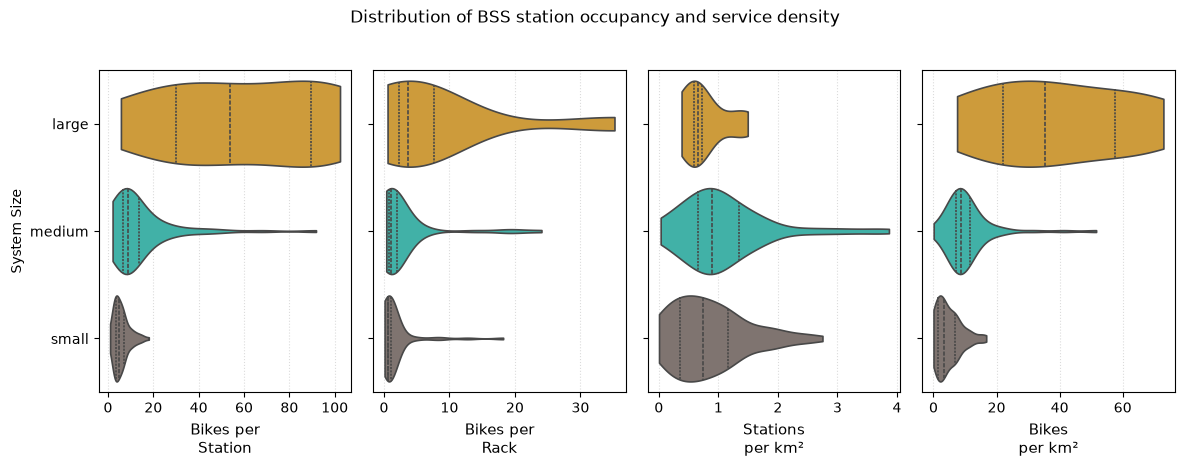

In [20]:
# Fig 4
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}

# NOTE: only consider station based BSS, replace free floating with NA.
plot_data = city_all.assign(
    bikes_per_station=city_all["n_bikes"].div(city_all["n_stations"].replace(0, np.nan)),
    bikes_per_rack=city_all["n_bikes"].div(city_all["n_racks"].replace(0, np.nan)),
    stations_per_sq_km=city_all["n_stations"].div(city_all["area_sq_km"].replace(0, np.nan)),
    bikes_per_sq_km=city_all["n_bikes"].div(city_all["area_sq_km"].replace(0, np.nan)),
).melt(
    id_vars="size",
    value_vars=[
        "bikes_per_station",
        "bikes_per_rack",
        "stations_per_sq_km",
        "bikes_per_sq_km",
    ],
    var_name="indicator",
    value_name="value",
).dropna(subset=["value"])

indicators = [
    ("bikes_per_station", "Bikes per\nStation"),
    ("bikes_per_rack", "Bikes per\nRack"),
    ("stations_per_sq_km", "Stations\nper km²"),
    ("bikes_per_sq_km", "Bikes\nper km²"),
]
fig, axes = plt.subplots(1, len(indicators), figsize=(12, 4.5), sharey=True)

for ax, (indicator, label) in zip(axes, indicators):
    sns.violinplot(
        data=plot_data[plot_data["indicator"] == indicator],
        x="value",
        y="size",
        hue="size",
        order=size_order,
        hue_order=size_order,
        palette=size_palette,
        dodge=False,
        cut=0,
        inner="quart",
        linewidth=1.2,
        legend=False,
        ax=ax,
    )
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel("System Size" if ax is axes[0] else "")
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False)
    ax.grid(axis="x", linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)

fig.suptitle("Distribution of BSS station occupancy and service density", y=1.03)
fig.tight_layout()
# fig.savefig("images/bss_indicators_by_system_size.png", dpi=300, bbox_inches="tight")
plt.show()

The violin plot shows the statistical distribution of station occupancy and service density. Inner lines denote the quartiles.

Three specific indicators (bikes per station/rack, bikes per square meter) are proportional to system size, with stasions per square meter being the exception. This shows that overall, smaller systems exhibit less dense coverage by stations and racks as well as by bikes. However, large systems (fleet size > 500) tend to have less stations but much heavier bike density in these stations.

### Overview of BSS systems.

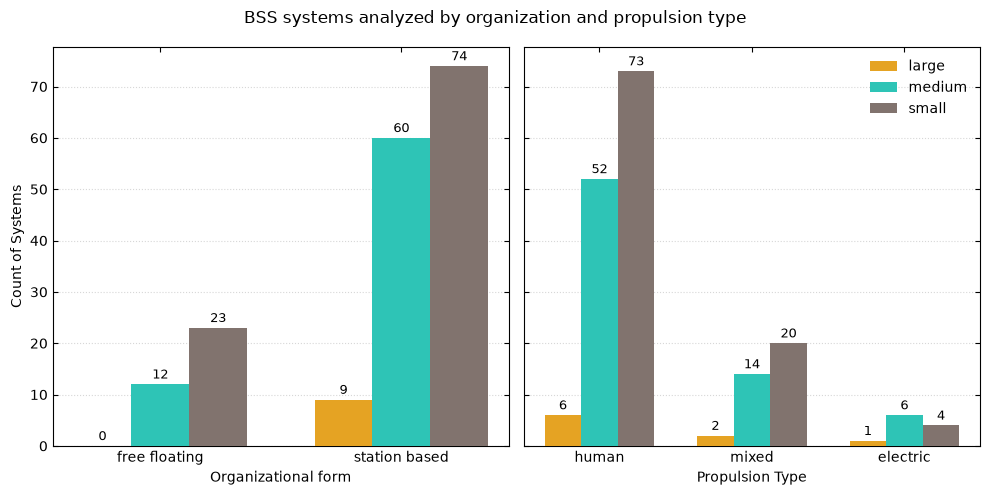

In [21]:
# Fig 5
size_order = ["large", "medium", "small"]
size_palette = {"large": "#e5a323", "medium": "#2ec4b6", "small": "#81736e"}
size_labels = {"large": "large", "medium": "medium", "small": "small"}

organization_counts = pd.crosstab(
    city_all["return_to_official_only"].map({False: "free floating", True: "station based"}),
    city_all["size"],
).reindex(index=["free floating", "station based"], columns=size_order, fill_value=0)
propulsion_counts = pd.crosstab(
    city_all["type"].replace({"conventional": "human"}),
    city_all["size"],
).reindex(index=["human", "mixed", "electric"], columns=size_order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
bar_width = 0.24

for ax, counts, xlabel in zip(
    axes,
    [organization_counts, propulsion_counts],
    ["Organizational form", "Propulsion Type"],
):
    positions = np.arange(len(counts.index))
    for i, size in enumerate(size_order):
        bars = ax.bar(
            positions + (i - 1) * bar_width,
            counts[size].to_numpy(),
            width=bar_width,
            label=size_labels[size],
            color=size_palette[size],
            zorder=3,
        )
        ax.bar_label(bars, padding=2, fontsize=9)

    ax.set_xticks(positions, counts.index)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", linestyle=":", alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)

axes[0].set_ylabel("Count of Systems")
axes[1].legend(title=None, frameon=False, loc="upper right")
fig.suptitle("BSS systems analyzed by organization and propulsion type")
fig.tight_layout()
# fig.savefig("images/bss_system_counts_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
size_indicators

,n_systems,avg_bikes_per_station,avg_bikes_per_rack,avg_bikes_per_sq_km,avg_stations_per_sq_km,share_station_based_bss_pct,share_mixed_propulsion_bss_pct,share_electric_bss_pct
size,,,,,,,,
small,97,5.758213,1.567236,4.675725,0.844523,76.288660,20.618557,4.123711
medium,72,14.021020,2.691682,10.624351,1.083457,83.333333,19.444444,8.333333
large,9,60.087447,8.014312,39.070115,0.764905,100.000000,22.222222,11.111111


**In terms of Organizational form:**

Most BSS are station based, including all large BSS. Small BSS are more likely to be free floating or hybrid compared to medium systems with respective likelihoods of 24% and 17%.

**In terms of Propulsion type:**

Most BSS are classic BSS. Medium and large BSS are more likely to be purely electric than small systems (11% and 8%, compared to 4%).


### Temporal characteristics of trips

We plot the hourly relative shares of trip starts, each subplot for a pair of opposing characteristics.

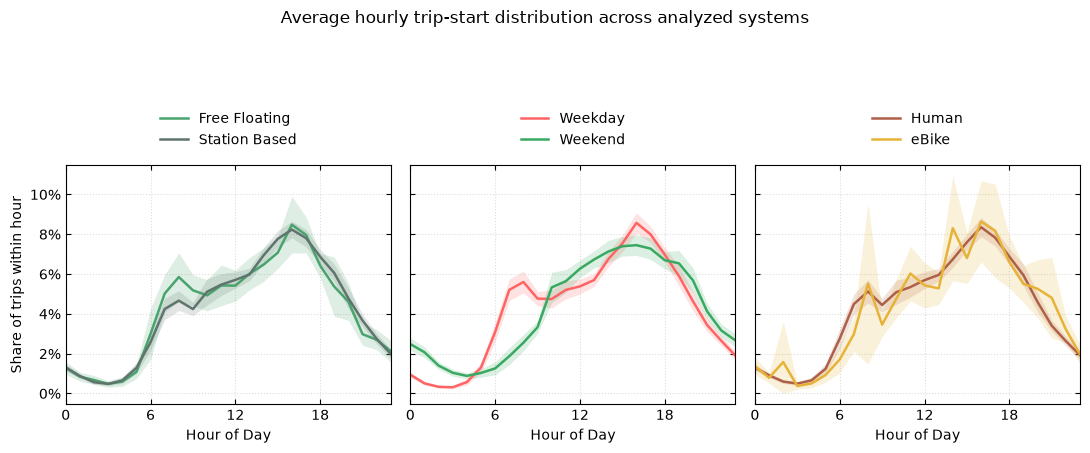

In [23]:
from matplotlib.ticker import PercentFormatter

# Restrict temporal profiles to the systems included in df and trips with known propulsion.
temporal_trips = (
    trips.merge(
        bike_propulsion_type[["bike_id", "propulsion_type"]],
        on="bike_id",
        how="inner",
    )
    .merge(city_all[["city_id", "return_to_official_only"]], on="city_id", how="inner")
    .merge(
        cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
        on="city_id",
        how="left",
    )
)
if temporal_trips["timezone"].isna().any():
    raise ValueError("A trip city is missing its timezone.")

temporal_trips["hour"] = 0
temporal_trips["day_type"] = ""
for timezone, row_indices in temporal_trips.groupby("timezone").groups.items():
    local_time = pd.to_datetime(
        temporal_trips.loc[row_indices, "time_start"], unit="s", utc=True
    ).dt.tz_convert(timezone)
    temporal_trips.loc[row_indices, "hour"] = local_time.dt.hour.to_numpy()
    temporal_trips.loc[row_indices, "day_type"] = np.where(
        local_time.dt.day_of_week.to_numpy() < 5, "Weekday", "Weekend"
    )

temporal_trips["organization"] = temporal_trips["return_to_official_only"].map(
    {False: "Free Floating", True: "Station Based"}
)
temporal_trips["propulsion"] = temporal_trips["propulsion_type"].map(
    {"human": "Human", "electric_assist": "eBike"}
)


def hourly_mean_ci(group):
    counts = (
        group.groupby(["city_id", "hour"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=range(24), fill_value=0)
    )
    system_shares = counts.div(counts.sum(axis=1), axis=0)
    mean = system_shares.mean(axis=0).to_numpy()
    margin = (1.96 * system_shares.sem(axis=0).fillna(0)).to_numpy()
    return mean, margin


panels = [
    (
        "organization",
        [("Free Floating", "#48a36c"), ("Station Based", "#60746e")],
    ),
    ("day_type", [("Weekday", "#ff6464"), ("Weekend", "#39a962")]),
    ("propulsion", [("Human", "#ad6047"), ("eBike", "#e6b338")]),
]
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
hours = np.arange(24)

for ax, (group_column, categories) in zip(axes, panels):
    for category, color in categories:
        mean, margin = hourly_mean_ci(
            temporal_trips[temporal_trips[group_column] == category]
        )
        ax.plot(hours, mean, color=color, linewidth=1.8, label=category)
        ax.fill_between(
            hours,
            np.maximum(mean - margin, 0),
            mean + margin,
            color=color,
            alpha=0.18,
            linewidth=0,
        )

    ax.set_xlim(0, 23)
    ax.set_xticks([0, 6, 12, 18])
    ax.set_xlabel("Hour of Day")
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(linestyle=":", alpha=0.45)
    ax.set_axisbelow(True)
    ax.tick_params(direction="in", top=True, right=True)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02))

axes[0].set_ylabel("Share of trips within hour")
fig.suptitle("Average hourly trip-start distribution across analyzed systems", y=1.12)
fig.tight_layout()
fig.savefig("images/bss_temporal_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In general, night usage is low.

**Left:** 

Free floating BSS has two usage peaks, at 8 a.m. and 5 p.m, corresponding to the typecal rush hour. In contrast, station based BSS has only one peak at 5 p.m.

**Middle:**

During the week, bike usage peaks at 8 a.m and 5 p.m. On weekends, bike usage remain relatively low untill 9 a.m., showing people go out later on weekends than on weekdays. The usage on weekends has a plateau from 10 a.m. to the end of the day, with no high peaks as observed on weekdays.

**Right:**

The usage of human-powered bikes and electric bikes follows a similar pattern, only that the curve of eBike fluctuates heavily. We suggest that there might be a data quality issue regarding trips made by electric bikes.